# Додаткове завдання. Похідні: чисельні методи та криві Безьє❤️

Привіт! У цій лабораторній роботі ви чисельно знайдете похідну функції в точці, порівняєте кілька методів пошуку екстремуму, а потім застосуєте все це до **кривих Безьє** — тих самих кривих, з яких складаються шрифти, логотипи, SVG-графіка та інструмент «перо» в Illustrator чи Inkscape.

Максимальна кількість балів за лабораторну роботу -- $\textbf{2 бали}$:
- Частина A. Чисельні методи -- $\textbf{1 бал}$
- Частина B. Криві Безьє -- $\textbf{1 бал}$

Для початку слід обрати функцію, над якою ви працюватимете:
1. $x\cdot e^{-\frac{x^2}{8}}$

2. $x^2 - 4\ln(x+1)$

3. $\sin x + \dfrac{x}{2}$

4. $\dfrac{\ln x}{x}$

5. $x + \dfrac{4}{x}$

In [1]:
student_id = 69 # замініть на суму чисел свого номера телефону
assigned_function = student_id % 5 + 1
print(f"+++ Номер функції: {assigned_function} +++")

+++ Номер функції: 5 +++


Далі імпортуємо необхідні бібліотеки і починаємо!

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Частина A. Чисельні методи (1 бал)

### A1. Графік функції (0.1 б)

Для початку слід поглянути, як виглядає функція на графіку.
Намалюйте графік функції, використовуючи numpy та matplotlib.

**Важливо:** використовуйте функції з numpy (`np.exp`, `np.log`, `np.sin`), а не з `math` -- тоді формула працюватиме для цілого масиву значень.

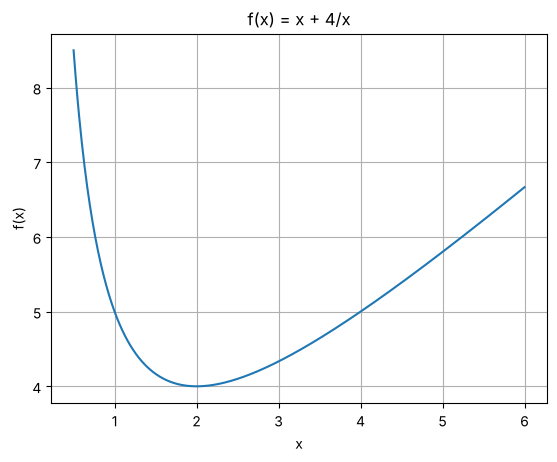

In [3]:
f = lambda x: x + 4 / x # функція 5

a, b = 0.5, 6 # на цьому відрізку є рівно один екстремум
x_values = np.linspace(a, b, 500)
y_values = f(x_values)

plt.plot(x_values, y_values)
plt.title("f(x) = x + 4/x")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.show()

Знайдіть аналітично точку екстремуму $x^*$ на вашому відрізку (розвʼяжіть $f'(x) = 0$) та визначте, мінімум це чи максимум. Це точне значення знадобиться для порівняння методів.

**Ваша відповідь:**

$f(x) = x + \dfrac{4}{x}$, область визначення $x \neq 0$.

$$
f'(x) = 1 - \frac{4}{x^2} = 0 \;\Rightarrow\; x^2 = 4 \;\Rightarrow\; x = \pm 2
$$

На відрізку $[0.5,\ 6]$ лежить тільки $x^* = 2$.

Перевіряємо знак похідної: при $x < 2$ (наприклад, $x = 1$) $f'(1) = -3 < 0$, функція спадає; при $x > 2$ (наприклад, $x = 4$) $f'(4) = 0.75 > 0$, функція зростає. Отже, $x^* = 2$ -- **точка мінімуму**, $f(2) = 2 + 2 = 4$.

(Також $f''(x) = \dfrac{8}{x^3}$, $f''(2) = 1 > 0$ -- мінімум.)

### A2. Чисельна похідна (0.25 б)

Як ви памʼятаєте, похідна є границею відношення приросту функції до приросту її аргументу, коли приріст аргументу прямує до нуля.
$$
f'(x_0) = \lim\limits_{h \to 0 } \dfrac{f(x_0+h)-f(x_0)}{h}
$$

Ми можемо порахувати наближене значення похідної в точці, взявши дуже мале $h$.
Запишіть формулу, яка рахуватиме похідну за наданою формулою.

In [4]:
df_forward = lambda x, h: (f(x + h) - f(x)) / h

Існує інший метод визначення приблизного значення похідної через центральну різницю.
Детальніше можна почитати тут: https://adamdjellouli.com/articles/numerical_methods/3_differentiation/central_difference

Запишіть формулу, щоб порахувати наближене значення похідної в точці, використовуючи центральну різницю.

In [5]:
df_central = lambda x, h: (f(x + h) - f(x - h)) / (2 * h)

Порівняйте, яка з цих формул дає більш точне значення. Яка похибка обчислених значень? Спробуйте порахувати похибки на певному інтервалі значень та знайдіть максимальну для обох формул. На основі цього оберіть, якою формулою користуватиметесь далі.

In [6]:
df_exact = lambda x: 1 - 4 / x**2 # точна похідна, знайдена в A1

x_check = np.linspace(a, b, 1000)

for h in [0.1, 0.01, 0.001, 0.0001, 0.00001]:
    err_forward = np.max(np.abs(df_forward(x_check, h) - df_exact(x_check)))
    err_central = np.max(np.abs(df_central(x_check, h) - df_exact(x_check)))
    print(f"h = {h}: max похибка forward = {err_forward:.2e}, max похибка central = {err_central:.2e}")

h = 0.1: max похибка forward = 2.67e+00, max похибка central = 6.67e-01
h = 0.01: max похибка forward = 3.14e-01, max похибка central = 6.40e-03
h = 0.001: max похибка forward = 3.19e-02, max похибка central = 6.40e-05
h = 0.0001: max похибка forward = 3.20e-03, max похибка central = 6.40e-07
h = 1e-05: max похибка forward = 3.20e-04, max похибка central = 6.36e-09


**Висновок:** центральна різниця дає набагато точніший результат. Коли зменшуємо $h$ у 10 разів, похибка правої різниці зменшується приблизно в 10 разів, а центральної -- приблизно в 100 разів. Найбільша похибка в обох формулах -- біля лівого кінця $x = 0.5$, де функція змінюється найшвидше.

Далі користуємось **центральною різницею**.

### A3. Друга похідна (0.1 б)

Тепер давайте запишемо формулу, яка рахуватиме приблизне значення другої похідної в точці. Для цього використаймо центральну різницю для другої похідної.
Давайте її виведемо!\
Друга похідна -- це "зміна нахилу", тобто зміна "стрімкості" чи швидкості функції. Щоб знайти центральну різницю, позначимо нахил попереду та позаду (крок вправо і вліво)\
$$
g_{fwd} \approx \dfrac{f(x+h)-f(x)}{h} \qquad g_{bwd} \approx \dfrac{f(x)-f(x-h)}{h}
$$
Тепер знайдемо зміну цих нахилів, поділивши різницю на крок $h$.
$$
f''(x) \approx \dfrac{\dfrac{f(x+h)-f(x)}{h} - \dfrac{f(x)-f(x-h)}{h}}h
$$
$$
f''(x) \approx \dfrac{f(x+h) - 2f(x)+f(x-h)}{h^2}
$$

Тепер запишіть формулу, використовуючи виведений вираз❤️

In [7]:
d2f_central = lambda x, h: (f(x + h) - 2 * f(x) + f(x - h)) / h**2

# перевірка з точною другою похідною f''(x) = 8 / x^3
for x0 in [1, 2, 4]:
    print(f"x = {x0}: наближено {d2f_central(x0, 1e-4):.6f}, точно {8 / x0**3:.6f}")

x = 1: наближено 8.000000, точно 8.000000
x = 2: наближено 1.000000, точно 1.000000
x = 4: наближено 0.125000, точно 0.125000


В наступних пунктах ми порівняємо кілька методів знаходження екстремуму: метод бісекції, метод золотого перерізу, а також метод Ньютона.
Детальніше про ці методи можете почитати за посиланнями:
- Метод бісекції: https://adamdjellouli.com/articles/numerical_methods/1_root_and_extrema_finding/bisection_method
- Метод золотого перерізу: https://adamdjellouli.com/articles/numerical_methods/1_root_and_extrema_finding/golden_ratio_search
- Метод Ньютона: https://adamdjellouli.com/articles/numerical_methods/1_root_and_extrema_finding/newtons_method

### A4. Метод бісекції (0.2 б)

Як ви знаєте, екстремумом функції є точка, в якій похідна дорівнює нулю. Ми можемо використати метод бісекції на похідній, знайти її нуль, а отже і точку екстремуму.

In [8]:
df = lambda x: df_central(x, 1e-6)

left, right = a, b
tol = 1e-8
iterations_bisection = 0

# Ваш код: знайдіть корінь df на [a, b] методом бісекції з точністю tol
while right - left > tol:
    mid = (left + right) / 2
    if df(left) * df(mid) <= 0: # знак змінюється на лівій половині
        right = mid
    else:
        left = mid
    iterations_bisection += 1

x_bisection = (left + right) / 2
print(f"Бісекція: x = {x_bisection}, ітерацій: {iterations_bisection}")

Бісекція: x = 2.000000001164153, ітерацій: 30


### A5. Метод золотого перерізу (0.15 б)

В методі бісекції ми ділили наш відрізок навпіл. В методі золотого перерізу ми використаємо константу золотого перерізу (золоте число $\varphi$) для поділу відрізка.

**Важливо:** метод шукає **мінімум**. Якщо у вас максимум -- шукайте мінімум функції $-f(x)$.

In [9]:
g = lambda x: f(x) # функція, мінімум якої шукаємо (у нас мінімум, тому просто f)

phi = (1 + 5 ** 0.5) / 2
left, right = a, b
tol = 1e-8
iterations_golden = 0

# Ваш код: знайдіть мінімум g на [a, b] методом золотого перерізу з точністю tol
while right - left > tol:
    x1 = right - (right - left) / phi
    x2 = left + (right - left) / phi
    if g(x1) < g(x2): # мінімум на [left, x2]
        right = x2
    else:             # мінімум на [x1, right]
        left = x1
    iterations_golden += 1

x_golden = (left + right) / 2
print(f"Золотий переріз: x = {x_golden}, ітерацій: {iterations_golden}")

Золотий переріз: x = 2.000000031251762, ітерацій: 42


### A6. Метод Ньютона (0.1 б)

Метод Ньютона працює наступним чином. Починається пошук у заданій точці, яка, в ідеалі, близька до кореня. У ній перевіряється значення, і якщо воно недостатньо близьке до бажаного, то наступну точку визначаємо за формулою:
$$
x_{n+1} = x_n - \dfrac{g(x_n)}{g'(x_n)}
$$
Шукаємо $x_i$: $g(x_i) \approx 0$.
Для того щоб знайти екстремум, ми працюватимемо над похідною, отже тут $g(x_n) := f'(x_n)$. Відповідно її похідна вже буде другою похідною базової функції $f(x)$.

In [10]:
x_newton = 1 # початкове наближення x0: оберіть самі
tol = 1e-8
max_iter = 100
iterations_newton = 0

# Ваш код
d2f = lambda x: d2f_central(x, 1e-4)

for i in range(max_iter):
    x_next = x_newton - df(x_newton) / d2f(x_newton)
    iterations_newton += 1
    if abs(x_next - x_newton) < tol:
        x_newton = x_next
        break
    x_newton = x_next

print(f"Ньютон: x = {x_newton}, ітерацій: {iterations_newton}")

Ньютон: x = 2.0000000001105755, ітерацій: 7


### A7. Порівняння методів (0.1 б)

Порівняйте ці методи (за потреби можете написати додатковий скрипт): які з цих методів є більш ефективними, які дають більш точні результати?

Метод            | x                  | похибка   | ітерацій
Бісекція         | 2.000000001164153 | 1.2e-09   | 30
Золотий переріз  | 2.000000031251762 | 3.1e-08   | 42
Ньютон           | 2.000000000110576 | 1.1e-10   | 7


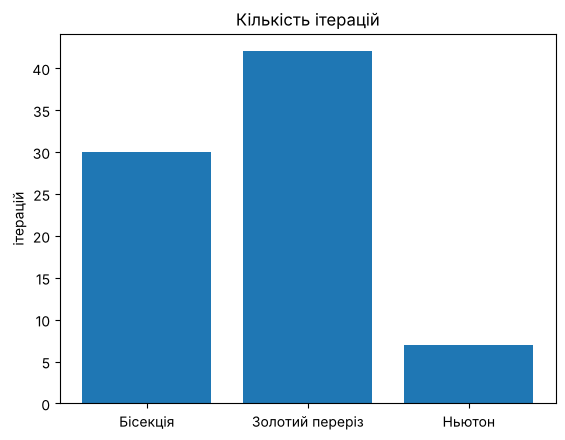

In [11]:
x_star = 2 # точне значення з A1

print("Метод            | x                  | похибка   | ітерацій")
print(f"Бісекція         | {x_bisection:.15f} | {abs(x_bisection - x_star):.1e}   | {iterations_bisection}")
print(f"Золотий переріз  | {x_golden:.15f} | {abs(x_golden - x_star):.1e}   | {iterations_golden}")
print(f"Ньютон           | {x_newton:.15f} | {abs(x_newton - x_star):.1e}   | {iterations_newton}")

methods = ["Бісекція", "Золотий переріз", "Ньютон"]
iterations = [iterations_bisection, iterations_golden, iterations_newton]
plt.bar(methods, iterations)
plt.title("Кількість ітерацій")
plt.ylabel("ітерацій")
plt.show()

**Висновок:**
- **Метод Ньютона** знайшов екстремум найшвидше (найменше ітерацій) і найточніше. Але йому потрібна друга похідна і початкове наближення, близьке до відповіді.
- **Бісекція** робить більше ітерацій, бо щоразу ділить відрізок лише навпіл, зате завжди спрацьовує, якщо похідна на кінцях має різні знаки.
- **Золотий переріз** зробив найбільше ітерацій (відрізок зменшується лише в $\varphi \approx 1.618$ разів) і дав найменш точну відповідь, бо біля мінімуму значення функції майже однакові і їх важко розрізнити. Зате йому не потрібні похідні.

Отже, найефективніший -- метод Ньютона, а бісекція і золотий переріз простіші й надійніші.

## Частина B. Криві Безьє (1 бал)

### Що таке крива Безьє?

Як компʼютер малює плавну літеру «S» чи логотип? Зберігати тисячі точок контуру незручно. Натомість зберігають кілька **контрольних точок** $P_0, P_1, \ldots, P_n$, а саму криву обчислюють за формулою. Такі криві придумали інженери автомобільних компаній П'єр Безьє (Renault) та Поль де Кастельжо (Citroën) для проєктування кузовів. Сьогодні вони всюди: шрифти, SVG, Canva, Blender, Illustrator, CSS-анімації.

Крива Безьє -- це **параметрично задана функція**: кожному значенню параметра $t \in [0, 1]$ відповідає точка $B(t) = \big(x(t), y(t)\big)$. Можна уявляти, що $t$ -- це час, а $B(t)$ -- положення точки, яка рухається вздовж кривої.

Дуже рекомендуємо переглянути відео про те, як влаштовані криві Безьє: https://www.youtube.com/watch?v=aVwxzDHniEw

### Побудова де Кастельжо

Почнемо з найпростішого. **Лінійна інтерполяція** між точками $P_0$ і $P_1$:
$$
B(t) = (1-t)P_0 + tP_1
$$
Це просто відрізок: при $t = 0$ ми в $P_0$, при $t = 1$ -- в $P_1$, а при $t = 0.3$ точка пройшла 30% шляху. (Множення точки на число і додавання точок робимо покоординатно.)

**Алгоритм де Кастельжо** будує криву повторною лінійною інтерполяцією:
1. Зʼєднуємо сусідні контрольні точки відрізками.
2. На кожному відрізку беремо точку в тій самій пропорції $t$.
3. Отримали нові точки -- на одну менше. Повторюємо, доки не залишиться одна точка. Це і є $B(t)$.

Коли $t$ пробігає значення від 0 до 1, точка $B(t)$ малює криву.

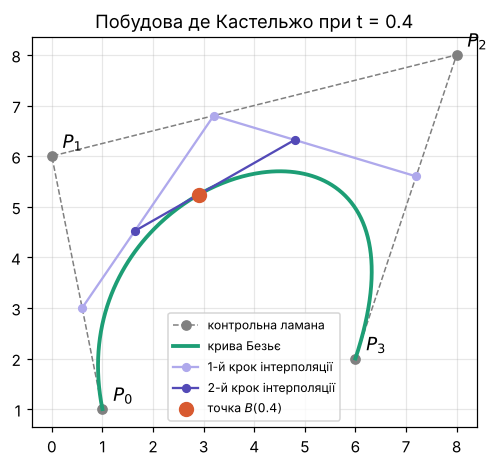

Запустіть готову клітинку нижче. Вона створює функцію `draw_control_polygon`, яка малює контрольні точки з підписами та ламану між ними. Як вона влаштована всередині, розбирати не обовʼязково -- її достатньо викликати, як `print`.

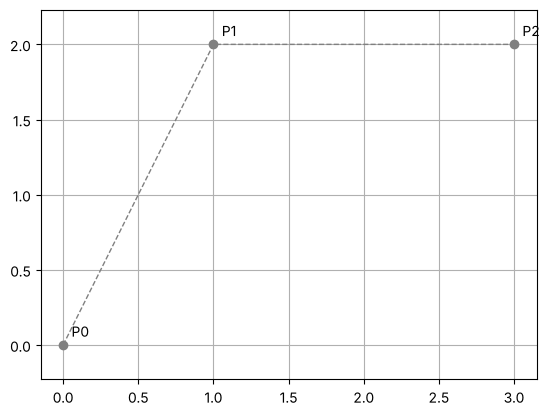

In [12]:
def draw_control_polygon(points, name="P", color="gray"):
    xs = [p[0] for p in points]
    ys = [p[1] for p in points]
    plt.plot(xs, ys, "--o", color=color, linewidth=1)
    for i in range(len(points)):
        plt.annotate(f"{name}{i}", (xs[i], ys[i]), textcoords="offset points", xytext=(6, 6))

# приклад використання
draw_control_polygon([[0, 0], [1, 2], [3, 2]])
plt.axis("equal")
plt.grid(True)
plt.show()

### B1. Формула кривої (0.2 б)

Виведіть формулу **квадратичної** кривої Безьє з контрольними точками $P_0, P_1, P_2$. Для цього застосуйте алгоритм де Кастельжо: запишіть дві лінійні інтерполяції ($P_0 \to P_1$ та $P_1 \to P_2$), потім інтерполяцію між отриманими точками, і розкрийте дужки.

**Ваша відповідь:**

Дві лінійні інтерполяції:
$$
Q_0 = (1-t)P_0 + tP_1, \qquad Q_1 = (1-t)P_1 + tP_2
$$
Інтерполяція між ними:
$$
B(t) = (1-t)Q_0 + tQ_1 = (1-t)\big[(1-t)P_0 + tP_1\big] + t\big[(1-t)P_1 + tP_2\big]
$$
Розкриваємо дужки:
$$
B(t) = (1-t)^2P_0 + (1-t)t\,P_1 + t(1-t)\,P_1 + t^2P_2 = (1-t)^2P_0 + 2(1-t)t\,P_1 + t^2P_2
$$

Для **кубічної** кривої (4 контрольні точки) той самий алгоритм дає формулу:
$$
B(t) = (1-t)^3P_0 + 3(1-t)^2t\,P_1 + 3(1-t)t^2\,P_2 + t^3P_3, \qquad t \in [0, 1]
$$
Саме кубічні криві найчастіше використовуються на практиці.

✍️ Перевірте, що формула узгоджується з побудовою:
1. Підставте $t = 0$ і $t = 1$. Через які точки проходить крива?
2. Доведіть, що сума коефіцієнтів при $P_0, P_1, P_2, P_3$ дорівнює 1 для будь-якого $t$. *Підказка:* $(1-t) + t = 1$. Що буде, якщо піднести це до куба? Чому це означає, що $B(t)$ -- «зважене середнє» контрольних точок?
3. Обчисліть вручну $B(0.5)$ для точок нижче.

**Ваша відповідь:**

**1.** $B(0) = 1\cdot P_0 + 0 + 0 + 0 = P_0$, $\quad B(1) = 0 + 0 + 0 + 1\cdot P_3 = P_3$.
Крива проходить через $P_0$ і $P_3$ (через $P_1$ і $P_2$ -- загалом ні).

**2.**
$$
1 = \big((1-t) + t\big)^3 = (1-t)^3 + 3(1-t)^2t + 3(1-t)t^2 + t^3
$$
Це якраз сума коефіцієнтів при $P_0, P_1, P_2, P_3$, тому вона дорівнює 1 для будь-якого $t$. Для $t \in [0, 1]$ всі коефіцієнти ще й невідʼємні, тобто це «ваги», які в сумі дають 1. Тому $B(t)$ -- зважене середнє контрольних точок.

**3.** При $t = 0.5$ коефіцієнти: $\frac18, \frac38, \frac38, \frac18$.
$$
x = \frac{1 + 3\cdot 0 + 3\cdot 8 + 6}{8} = \frac{31}{8} = 3.875, \qquad
y = \frac{1 + 3\cdot 6 + 3\cdot 8 + 2}{8} = \frac{45}{8} = 5.625
$$
$$
B(0.5) = (3.875;\ 5.625)
$$

Тепер побудуємо криву. Запишіть формули для $x(t)$ та $y(t)$ окремо: у $x(t)$ підставляються лише $x$-координати точок (`P0[0]`, `P1[0]`, ...), у $y(t)$ -- лише $y$-координати (`P0[1]`, ...).

Побудуйте криву разом із контрольною ламаною та позначте на ній точку $B(0.5)$. Чи збігається вона з вашим ручним обчисленням?

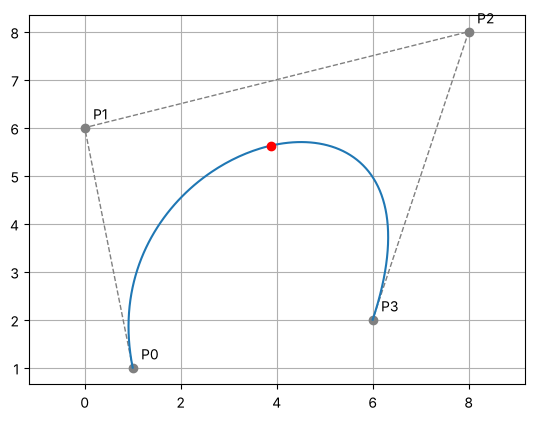

B(0.5) = 3.875 5.625


In [13]:
P0 = [1, 1]
P1 = [0, 6]
P2 = [8, 8]
P3 = [6, 2]

bx = lambda t: (1-t)**3 * P0[0] + 3*(1-t)**2*t * P1[0] + 3*(1-t)*t**2 * P2[0] + t**3 * P3[0] # x(t) кубічної кривої
by = lambda t: (1-t)**3 * P0[1] + 3*(1-t)**2*t * P1[1] + 3*(1-t)*t**2 * P2[1] + t**3 * P3[1] # y(t)

t = np.linspace(0, 1, 200)

draw_control_polygon([P0, P1, P2, P3])
# Ваш код: побудуйте криву та позначте точку B(0.5)
plt.plot(bx(t), by(t))
plt.plot(bx(0.5), by(0.5), "ro")
plt.axis("equal")
plt.grid(True)
plt.show()

print("B(0.5) =", bx(0.5), by(0.5)) # збігається з ручним обчисленням (3.875, 5.625)

### B2. Похідна кривої (0.25 б)

Вектор $B'(t) = \big(x'(t), y'(t)\big)$ -- це **швидкість** точки, що рухається вздовж кривої. Він напрямлений по дотичній. Нахил дотичної, як ви знаєте з похідної параметрично заданої функції:
$$
\dfrac{dy}{dx} = \dfrac{y'(t)}{x'(t)}
$$

1. Знайдіть похідну $B'(t)$ кубічної кривої Безьє (у загальному вигляді, через $P_0, \ldots, P_3$). Спробуйте згрупувати доданки так, щоб у відповіді були різниці $P_1 - P_0$, $P_2 - P_1$, $P_3 - P_2$.

2. Доведіть, що $B'(0) = 3(P_1 - P_0)$ та $B'(1) = 3(P_3 - P_2)$. Що це означає геометрично? Згадайте режим «Змінити точки» у PowerPoint: біля кожної точки кривої є «ручки», які можна тягати. Що вони задають?

**Ваша відповідь:**

**1.** Похідні коефіцієнтів:
$$
\big((1-t)^3\big)' = -3(1-t)^2, \qquad \big(3(1-t)^2t\big)' = 3(1-t)^2 - 6(1-t)t,
$$
$$
\big(3(1-t)t^2\big)' = 6(1-t)t - 3t^2, \qquad (t^3)' = 3t^2.
$$
$$
B'(t) = -3(1-t)^2P_0 + \big[3(1-t)^2 - 6(1-t)t\big]P_1 + \big[6(1-t)t - 3t^2\big]P_2 + 3t^2P_3
$$
Групуємо:
$$
B'(t) = 3(1-t)^2(P_1 - P_0) + 6(1-t)t\,(P_2 - P_1) + 3t^2(P_3 - P_2)
$$

**2.** При $t = 0$ другий і третій доданки дорівнюють нулю, а $(1-0)^2 = 1$: $B'(0) = 3(P_1 - P_0)$.
При $t = 1$ перші два доданки дорівнюють нулю: $B'(1) = 3(P_3 - P_2)$.

Геометрично: у точці $P_0$ дотична до кривої йде в напрямку $P_1$, а в точці $P_3$ -- з напрямку $P_2$. Тобто «ручки» в PowerPoint -- це відрізки $P_0P_1$ і $P_2P_3$: вони задають напрямок дотичної в кінці кривої, а їх довжина -- наскільки сильно крива «тягнеться» в цей бік.

Запишіть $x'(t)$ та $y'(t)$ через `lambda`. Перевірте свою формулу: порівняйте її з центральною різницею з A2 у кількох точках $t$ (тут функція -- `bx` або `by`, а не `f`).

In [14]:
dbx = lambda t: 3*(1-t)**2 * (P1[0]-P0[0]) + 6*(1-t)*t * (P2[0]-P1[0]) + 3*t**2 * (P3[0]-P2[0]) # x'(t)
dby = lambda t: 3*(1-t)**2 * (P1[1]-P0[1]) + 6*(1-t)*t * (P2[1]-P1[1]) + 3*t**2 * (P3[1]-P2[1]) # y'(t)

# Ваш код: перевірка центральною різницею
h = 1e-5
for t0 in [0, 0.25, 0.5, 0.75, 1]:
    cx = (bx(t0 + h) - bx(t0 - h)) / (2 * h)
    cy = (by(t0 + h) - by(t0 - h)) / (2 * h)
    print(f"t = {t0}: x' = {dbx(t0):.6f} (центр. {cx:.6f}),  y' = {dby(t0):.6f} (центр. {cy:.6f})")

t = 0: x' = -3.000000 (центр. -3.000000),  y' = 15.000000 (центр. 15.000000)
t = 0.25: x' = 6.937500 (центр. 6.937500),  y' = 9.562500 (центр. 9.562500)
t = 0.5: x' = 9.750000 (центр. 9.750000),  y' = 2.250000 (центр. 2.250000)
t = 0.75: x' = 5.437500 (центр. 5.437500),  y' = -6.937500 (центр. -6.937500)
t = 1: x' = -6.000000 (центр. -6.000000),  y' = -18.000000 (центр. -18.000000)


Побудуйте криву та дотичні до неї в точках $t = 0$, $t = 0.5$ та $t = 1$. Виведіть нахил $\frac{dy}{dx}$ у цих точках.

*Підказка:* дотична в точці $t_0$ -- це відрізок, що проходить через $B(t_0)$ у напрямку $B'(t_0)$. Його точки: $B(t_0) + s \cdot B'(t_0)$, де $s$ змінюється, наприклад, від $-0.2$ до $0.2$.

t = 0: dy/dx = -5.0000
t = 0.5: dy/dx = 0.2308
t = 1: dy/dx = 3.0000


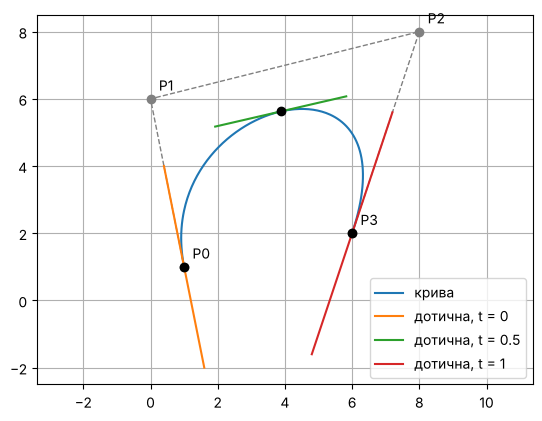

In [15]:
draw_control_polygon([P0, P1, P2, P3])
plt.plot(bx(t), by(t), label="крива")

s = np.linspace(-0.2, 0.2, 10)
for t0 in [0, 0.5, 1]:
    plt.plot(bx(t0) + s * dbx(t0), by(t0) + s * dby(t0), label=f"дотична, t = {t0}")
    plt.plot(bx(t0), by(t0), "ko")
    print(f"t = {t0}: dy/dx = {dby(t0) / dbx(t0):.4f}")

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

### B3. Найвища точка та рамка кривої (0.2 б)

Графічні редактори постійно розвʼязують таку задачу: знайти найменший прямокутник, у який вміщується крива (так звана *bounding box*, рамка, яку ви бачите, коли виділяєте обʼєкт). Для цього потрібні найвища, найнижча, найлівіша та найправіша точки кривої -- тобто екстремуми функцій $y(t)$ та $x(t)$ на відрізку $[0, 1]$.

Зверніть увагу: екстремум може бути як усередині відрізка (де похідна дорівнює нулю), так і на його кінцях $t = 0$ чи $t = 1$.

Похідна $y'(t)$ кубічної кривої -- це квадратний многочлен. Для наших точок запишіть $y'(t)$ у вигляді $\alpha t^2 + \beta t + \gamma$, розвʼяжіть рівняння $y'(t) = 0$ та залиште корені, що лежать на $[0, 1]$. Те саме зробіть для $x'(t)$. Які точки кривої є найвищою, найнижчою, найлівішою та найправішою?

**Ваша відповідь:**

Для наших точок: $P_1 - P_0 = (-1, 5)$, $P_2 - P_1 = (8, 2)$, $P_3 - P_2 = (-2, -6)$.

**Для $y(t)$:**
$$
y'(t) = 3\big[5(1-t)^2 + 4(1-t)t - 6t^2\big] = -15t^2 - 18t + 15
$$
$$
-15t^2 - 18t + 15 = 0 \;\Leftrightarrow\; 5t^2 + 6t - 5 = 0, \quad D = 36 + 100 = 136
$$
$$
t = \frac{-6 \pm \sqrt{136}}{10}: \quad t_1 \approx 0.5662 \in [0, 1], \quad t_2 \approx -1.766 \notin [0, 1]
$$
Порівнюємо значення: $y(0) = 1$, $y(1) = 2$, $y(0.5662) \approx 5.700$.
Отже, **найвища** точка -- при $t \approx 0.5662$: $B \approx (4.508;\ 5.700)$, **найнижча** -- при $t = 0$: $B = (1;\ 1)$.

**Для $x(t)$:**
$$
x'(t) = 3\big[-(1-t)^2 + 16(1-t)t - 2t^2\big] = -57t^2 + 54t - 3
$$
$$
19t^2 - 18t + 1 = 0, \quad D = 324 - 76 = 248, \quad t = \frac{18 \pm \sqrt{248}}{38}
$$
$$
t_3 \approx 0.0593, \quad t_4 \approx 0.8881 \quad \text{(обидва на } [0, 1])
$$
Порівнюємо: $x(0) = 1$, $x(1) = 6$, $x(0.0593) \approx 0.913$, $x(0.8881) \approx 6.322$.
Отже, **найлівіша** точка -- при $t \approx 0.0593$: $B \approx (0.913;\ 1.856)$, **найправіша** -- при $t \approx 0.8881$: $B \approx (6.322;\ 3.721)$.

Рамка: $x \in [0.913;\ 6.322]$, $y \in [1;\ 5.700]$.

Тепер знайдіть найвищу точку кривої **чисельно** методом золотого перерізу з A5 (на відрізку $[0, 1]$, для функції $y(t)$). Свій код з A5 можна скопіювати й змінити. Порівняйте з точним розвʼязком.

In [16]:
t_exact = (-6 + np.sqrt(136)) / 10 # ваш точний розвʼязок рівняння y'(t) = 0

# Ваш код: золотий переріз для y(t)
g_y = lambda t: -by(t) # шукаємо максимум y, тобто мінімум -y

left, right = 0, 1
tol = 1e-8
iterations = 0
while right - left > tol:
    t1 = right - (right - left) / phi
    t2 = left + (right - left) / phi
    if g_y(t1) < g_y(t2):
        right = t2
    else:
        left = t1
    iterations += 1

t_golden = (left + right) / 2
print(f"Золотий переріз: t = {t_golden}, ітерацій: {iterations}")
print(f"Точно: t = {t_exact}")
print(f"Похибка: {abs(t_golden - t_exact):.1e}")
print(f"Найвища точка: ({bx(t_golden):.4f}, {by(t_golden):.4f})")

Золотий переріз: t = 0.5661903834523887, ітерацій: 39
Точно: t = 0.5661903789690601
Похибка: 4.5e-09
Найвища точка: (4.5083, 5.7002)


Побудуйте криву, позначте на ній знайдені крайні точки та намалюйте рамку навколо кривої.

*Підказка:* прямокутник можна намалювати однією ламаною: `plt.plot([x_min, x_max, x_max, x_min, x_min], [y_min, y_min, y_max, y_max, y_min])`.

x від 0.9131 до 6.3224, y від 1.0000 до 5.7002


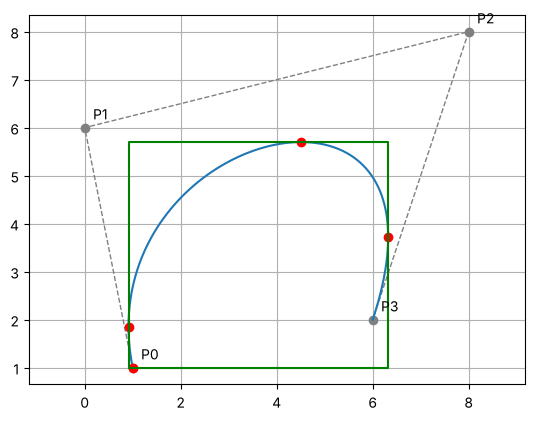

In [17]:
# корені x'(t) = 0 та y'(t) = 0, знайдені вище
t_left = (18 - np.sqrt(248)) / 38
t_right = (18 + np.sqrt(248)) / 38
t_low = 0
t_high = t_exact

x_min, x_max = bx(t_left), bx(t_right)
y_min, y_max = by(t_low), by(t_high)
print(f"x від {x_min:.4f} до {x_max:.4f}, y від {y_min:.4f} до {y_max:.4f}")

draw_control_polygon([P0, P1, P2, P3])
plt.plot(bx(t), by(t))
for tt in [t_left, t_right, t_low, t_high]:
    plt.plot(bx(tt), by(tt), "ro")
plt.plot([x_min, x_max, x_max, x_min, x_min], [y_min, y_min, y_max, y_max, y_min], "g")
plt.axis("equal")
plt.grid(True)
plt.show()

### B4. Склеювання кривих (0.15 б)

Одна кубічна крива може зробити лише один-два вигини. Складні контури (літери, логотипи) складаються з кількох кривих, склеєних кінець до кінця. Нехай перша крива має точки $A_0, A_1, A_2, A_3$, а друга -- $Q_0, Q_1, Q_2, Q_3$. Як склеїти їх без розривів і без «кутів»?

- **Неперервність** ($C^0$): друга крива починається там, де закінчується перша.
- **Гладкість** ($C^1$): у точці склеювання збігаються ще й похідні (вектори швидкості).

✍️ Користуючись результатом B2, запишіть умови $C^0$ та $C^1$ через контрольні точки. Для кривих нижче знайдіть $Q_0$ та $Q_1$ так, щоб склеювання було гладким.

**Ваша відповідь:**

**$C^0$:** друга крива починається в кінці першої: $Q_0 = A_3$.

**$C^1$:** з B2 похідна першої кривої в кінці $3(A_3 - A_2)$, другої на початку $3(Q_1 - Q_0)$. Прирівнюємо:
$$
3(A_3 - A_2) = 3(Q_1 - Q_0) \;\Rightarrow\; Q_1 = Q_0 + (A_3 - A_2) = 2A_3 - A_2
$$
Тобто $A_2$, $A_3$ і $Q_1$ лежать на одній прямій і $A_3$ -- середина $A_2Q_1$.

Для наших точок: $Q_0 = (4, 1)$, $Q_1 = 2\cdot(4, 1) - (3, 3) = (5, -1)$.

Побудуйте поруч два графіки: ліворуч -- склеювання з **розривом похідної** (злам), де $Q_0$ правильна, а $Q_1$ = `Q1_broken`; праворуч -- **гладке** склеювання з вашими точками.

*Підказка:* два графіки поруч: `plt.subplot(1, 2, 1)` перед першим і `plt.subplot(1, 2, 2)` перед другим. Формулу кривої з B1 доведеться записати ще раз для нових точок.

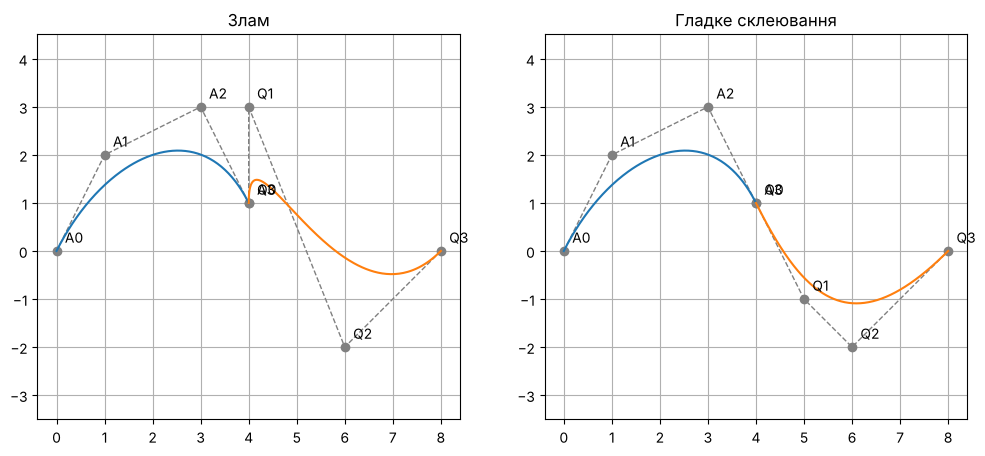

In [18]:
A0 = [0, 0]
A1 = [1, 2]
A2 = [3, 3]
A3 = [4, 1]

Q0 = [4, 1] # знайдіть
Q1 = [5, -1] # знайдіть
Q2 = [6, -2]
Q3 = [8, 0]

Q1_broken = [4, 3] # для лівого графіка

# Ваш код
# формула кубічної кривої для довільних точок
cx = lambda P, t: (1-t)**3 * P[0][0] + 3*(1-t)**2*t * P[1][0] + 3*(1-t)*t**2 * P[2][0] + t**3 * P[3][0]
cy = lambda P, t: (1-t)**3 * P[0][1] + 3*(1-t)**2*t * P[1][1] + 3*(1-t)*t**2 * P[2][1] + t**3 * P[3][1]

A = [A0, A1, A2, A3]
Q_broken = [Q0, Q1_broken, Q2, Q3]
Q_smooth = [Q0, Q1, Q2, Q3]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
draw_control_polygon(A, name="A")
draw_control_polygon(Q_broken, name="Q")
plt.plot(cx(A, t), cy(A, t))
plt.plot(cx(Q_broken, t), cy(Q_broken, t))
plt.title("Злам")
plt.axis("equal")
plt.grid(True)

plt.subplot(1, 2, 2)
draw_control_polygon(A, name="A")
draw_control_polygon(Q_smooth, name="Q")
plt.plot(cx(A, t), cy(A, t))
plt.plot(cx(Q_smooth, t), cy(Q_smooth, t))
plt.title("Гладке склеювання")
plt.axis("equal")
plt.grid(True)

plt.show()

### B5. Творче завдання (0.1 б)

Задійте свою фантазію і намалюйте з 2-3 гладко склеєних кубічних кривих щось своє: серце, хвилю, літеру свого імені, листочок тощо. Покажіть на малюнку контрольні точки. Склеювання мають бути гладкими (умова $C^1$), окрім тих місць, де ви навмисно робите гострий кут.

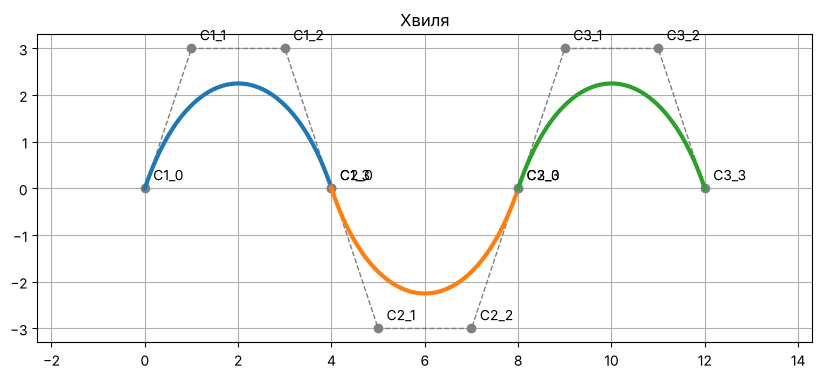

In [19]:
# Хвиля з трьох кубічних кривих. У кожному стику: Q0 = A3, Q1 = 2*A3 - A2 (умова C^1)
C1 = [[0, 0], [1, 3], [3, 3], [4, 0]]
C2 = [[4, 0], [5, -3], [7, -3], [8, 0]]   # 2*(4,0) - (3,3) = (5,-3)
C3 = [[8, 0], [9, 3], [11, 3], [12, 0]]   # 2*(8,0) - (7,-3) = (9,3)

plt.figure(figsize=(10, 4))
for i, C in enumerate([C1, C2, C3]):
    draw_control_polygon(C, name=f"C{i+1}_")
    plt.plot(cx(C, t), cy(C, t), linewidth=3)

plt.title("Хвиля")
plt.axis("equal")
plt.grid(True)
plt.show()

# Висновки🎉

### (0.1 б)
Вітаємо із завершенням! Вам лишилось трохи порефлексувати. Напишіть висновки, в яких опишіть роботу з кривими Безьє, яку ви проробили, результати обчислювальних методів, оцініть їхню ефективність.

**Ваша відповідь:**

У частині A ми працювали з функцією $f(x) = x + \dfrac{4}{x}$ і знайшли аналітично її мінімум $x^* = 2$ на відрізку $[0.5, 6]$. Порівняли дві формули чисельної похідної: центральна різниця виявилась значно точнішою за праву, тому далі використовували її. Також вивели і перевірили формулу для другої похідної.

Потім знайшли мінімум трьома методами. Усі три дали $x \approx 2$. Метод Ньютона виявився найефективнішим -- лише кілька ітерацій і найменша похибка. Бісекції знадобилось близько 30 ітерацій, а золотому перерізу -- найбільше, і він дав найменш точну відповідь. Зате бісекція і золотий переріз простіші і не залежать від вибору початкової точки.

У частині B ми вивели формулу квадратичної кривої Безьє з алгоритму де Кастельжо, перевірили властивості кубічної кривої і побудували її. Знайшли похідну кривої та переконались, що вона збігається з центральною різницею. Зрозуміли, що «ручки» в графічних редакторах задають дотичну в кінцях кривої. Знайшли рамку кривої через рівняння $x'(t) = 0$, $y'(t) = 0$, а найвищу точку також методом золотого перерізу -- результати збіглися. Нарешті, вивели умову гладкого склеювання $Q_1 = 2A_3 - A_2$ і з її допомогою намалювали хвилю з трьох кривих.